# Preprocessing and Simple Classification (C vs I)

## Overview

This notebook combines feature preprocessing and simple classification for the **Congruent vs Incongruent** task.

**Preprocessing**:
- Loads preprocessed `.fif` epoch files per subject
- Extracts STFT power features: Theta (5-7 Hz) at FCz and Alpha (8-12 Hz) at Oz in the 1000-1500 ms window
- Applies optional dimensionality reduction (PCA or ICA) and per-subject undersampling
- Saves the feature dataset to `.npz`

**Classification**:
- Mahalanobis-based outlier detection (reported but not removed)
- PCA cumulative variance analysis
- Per-subject cross-validated training of 5 model families: LR, LDA, RF, XGB, LGBM
- Accuracy distribution, ROC-AUC, and Precision-Recall AUC plots

In [56]:
import gc
import importlib.util
import os
import subprocess
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy.signal import stft
from scipy.stats import chi2, norm

from sklearn.decomposition import FastICA, PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    auc,
    average_precision_score,
    f1_score,
    precision_recall_curve,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

try:
    from google.colab import drive

    IN_COLAB = True
except ImportError:
    drive = None
    IN_COLAB = False

if IN_COLAB:
    required_packages = ["mne", "imbalanced-learn", "xgboost", "lightgbm"]
    for pkg in required_packages:
        if importlib.util.find_spec(pkg.replace("-", "_")) is None:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
    drive.mount("/content/drive", force_remount=False)

# Add src directory to path so we can import br_analysis
src_path = Path(r"c:\Users\nils\Documents\Universitat\TFG\src")
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from br_analysis.experiments import temporal_stratified_splits

warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    module="mne",
    message=".*does not conform to MNE naming conventions.*",
)
warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    module="mne",
    message=".*events passed to the Epochs constructor are not chronologically ordered.*",
)
mne.set_log_level("WARNING")

print("Imports and settings loaded.")

Imports and settings loaded.


In [ ]:
# ── Editable preprocessing pipeline settings ──────────────────────────
TASK_TAG = "c_vs_i"
DIMENSIONALITY_REDUCTION = "ICA"  # options: "PCA", "ICA" or None
TARGET_CHANNELS = {"theta": "FCz", "alpha": "Oz"}  # or "all_channels"
TARGET_WINDOW = (1.0, 1.5)
UNDERSAMPLING_PER_SUBJECT = True

print("Editable preprocessing settings loaded.")

Editable preprocessing settings loaded.


In [ ]:
if IN_COLAB:
    DRIVE_ROOT = Path("/content/drive/MyDrive")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"
else:
    DRIVE_ROOT = Path(r"H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"

BASE_DIR = PROJECT_DIR
DATA_DIR = PROJECT_DIR / "02_Data" / "01_Preprocessed_epochs"

ANALYSIS_ROOT = PROJECT_DIR / "04_Anàlisi"

CLASSIFICATION_DIR = ANALYSIS_ROOT / "02_classificacio"
FIGURES_DIR = CLASSIFICATION_DIR / "figures"
TABLES_DIR = CLASSIFICATION_DIR / "tables"
CACHE_DIR = CLASSIFICATION_DIR / "cache"

for folder in (DATA_DIR, ANALYSIS_ROOT, CLASSIFICATION_DIR, FIGURES_DIR, TABLES_DIR, CACHE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATA_FILES = sorted(DATA_DIR.glob("*.fif"))

COND_EVENTS = {
    "Congruent": ["event_1", "event_2"],
    "Incongruent_Pure": ["event_3", "event_4", "event_5", "event_6"],
    "Incongruent_Mixed": ["event_7", "event_8"],
    "Incongruent": ["event_3", "event_4", "event_5", "event_6", "event_7", "event_8"],
    "Errors": ["event_9", "event_10", "event_11", "event_12"],
}

EVENT_TO_LABEL = {
    1: "CRP",
    2: "CGP",
    3: "IPR",
    4: "IPR",
    5: "IPG",
    6: "IPG",
    7: "IM",
    8: "IM",
    9: "CRG",
    10: "CGG",
    11: "CRM",
    12: "CGM",
}

LABELS = {
    "Congruent": "Congruent (C)",
    "Incongruent_Pure": "Incongruent Pure (IP)",
    "Incongruent_Mixed": "Incongruent Mixed (IM)",
    "Incongruent": "Incongruent (I)",
    "Errors": "Errors",
}
COLORS = {
    "Congruent": "steelblue",
    "Incongruent_Pure": "darkorange",
    "Incongruent_Mixed": "forestgreen",
    "Incongruent": "slategray",
    "Errors": "firebrick",
}

TRIAL_START = -0.74
TRIAL_END = 1.5
FULL_TRIAL = (TRIAL_START, TRIAL_END)
BASELINE = (-0.74, -0.24)
RAMP_UP = (-0.24, 0.0)
STIM_ONSET = (0.0, 1.5)
STIM_OFFSET = (1.5, 2.0)
ERP_WINDOW = (0.0, 0.8)

WINDOW_1 = (0.0, 0.5)
WINDOW_2 = (0.5, 1.0)
WINDOW_3 = (1.0, 1.5)

FREQS_THETA = np.arange(5, 8)
FREQS_ALPHA = np.arange(8, 13)
FREQS_WIDE = np.arange(2, 21)

ROI_FRONTAL = ["Fz", "FCz", "Cz"]
ROI_PO = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2"]

EYE_LEFT_CODES = [3, 6]
EYE_RIGHT_CODES = [4, 5]
COLOR_RED_CODES = [1, 3, 4, 10]
COLOR_GREEN_CODES = [2, 5, 6, 9]
ERROR_CODES = [9, 10, 11, 12]

STFT_WINDOW_SEC = 0.5
STFT_STEP_SEC = 0.02

N_BINS = 10
RANDOM_STATE = 42
ICA_MAX_COMPONENTS = 20

print(f"Environment: {'Colab' if IN_COLAB else 'Local'}")
print(f"Project: {PROJECT_DIR}")
print(f"Data directory: {DATA_DIR}")
print(f"Classification results: {CLASSIFICATION_DIR}")
print(f"Cache directory: {CACHE_DIR}")
print(f".fif files found: {len(DATA_FILES)}")

Environment: Local
Project: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Data directory: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs
Classification results: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\02_classificacio
Cache directory: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\02_classificacio\cache
.fif files found: 47


In [81]:
def extract_subject_features(fif_path):
    ep = mne.read_epochs(fif_path, preload=True, verbose=False)
    for ch in ep.info["chs"]:
        ch["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
    ep.set_channel_types({ch: "eeg" for ch in ep.ch_names}, on_unit_change="ignore")

    required_channels = [TARGET_CHANNELS["theta"], TARGET_CHANNELS["alpha"]]
    missing = [ch for ch in required_channels if ch not in ep.ch_names]
    if missing:
        return None, f"{fif_path.name}: missing channels {missing}"

    ep = ep.copy().pick(required_channels).crop(tmin=TARGET_WINDOW[0], tmax=TARGET_WINDOW[1])

    c_names = [n for n in COND_EVENTS["Congruent"] if n in ep.event_id]
    pure_names = [n for n in COND_EVENTS["Incongruent_Pure"] if n in ep.event_id]
    mixed_names = [n for n in COND_EVENTS["Incongruent_Mixed"] if n in ep.event_id]
    i_names = [n for n in COND_EVENTS["Incongruent"] if n in ep.event_id]

    if not c_names or not i_names:
        return None, f"{fif_path.name}: no C or I trials"

    selected_names = c_names + i_names
    ep_bin = ep[selected_names]

    c_codes = [ep.event_id[n] for n in c_names]
    pure_codes = [ep.event_id[n] for n in pure_names]
    mixed_codes = [ep.event_id[n] for n in mixed_names]

    events = ep_bin.events[:, 2]
    y_detail = np.full(events.shape[0], "incongruent", dtype=object)
    y_detail[np.isin(events, c_codes)] = "congruent"
    y_detail[np.isin(events, pure_codes)] = "Incongruent_Pure"
    y_detail[np.isin(events, mixed_codes)] = "Incongruent_Mixed"
    y = np.where(y_detail == "congruent", 0, 1)

    x_data = ep_bin.get_data().astype(np.float32, copy=False)
    sfreq = ep_bin.info["sfreq"]
    nperseg = int(round(STFT_WINDOW_SEC * sfreq))
    hop = int(round(STFT_STEP_SEC * sfreq))
    noverlap = max(0, nperseg - hop)
    nfft = max(nperseg, int(round(sfreq)))

    f, t, z = stft(
        x_data,
        fs=sfreq,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft,
        boundary="zeros",
        padded=True,
        axis=-1,
    )
    power = np.abs(z) ** 2

    theta_idx = np.array([np.argmin(np.abs(f - fr)) for fr in FREQS_THETA])
    alpha_idx = np.array([np.argmin(np.abs(f - fr)) for fr in FREQS_ALPHA])

    theta_power = power[:, 0:1, theta_idx, :]
    alpha_power = power[:, 1:2, alpha_idx, :]

    X = np.concatenate(
        [theta_power.reshape(theta_power.shape[0], -1), alpha_power.reshape(alpha_power.shape[0], -1)],
        axis=1,
    )

    subject_summary = {
        "subject": fif_path.stem,
        "n_trials": int(len(y)),
        "n_c": int(np.sum(y == 0)),
        "n_i": int(np.sum(y == 1)),
        "n_ip": int(np.sum(y_detail == "Incongruent_Pure")),
        "n_im": int(np.sum(y_detail == "Incongruent_Mixed")),
        "n_features": int(X.shape[1]),
    }

    out = {
        "X": X,
        "y": y,
        "y_detail": y_detail,
        "subject": fif_path.stem,
        "summary": subject_summary,
    }
    return out, None

In [79]:
X_blocks, y_blocks, y_detail_blocks, subj_blocks = [], [], [], []
subject_rows = []
skipped = []

for fif_path in DATA_FILES:
    out, err = extract_subject_features(fif_path)
    if err is not None:
        skipped.append(err)
        continue

    X_blocks.append(out["X"])
    y_blocks.append(out["y"])
    y_detail_blocks.append(out["y_detail"])
    subj_blocks.extend([out["subject"]] * len(out["y"]))
    subject_rows.append(out["summary"])

if not X_blocks:
    raise RuntimeError("Unable to extract features from any subjects.")

X = np.vstack(X_blocks)
y = np.concatenate(y_blocks)
y_detail = np.concatenate(y_detail_blocks).astype(object)
subj_list = np.array(subj_blocks, dtype=object)

ICA_COMPONENTS = min(ICA_MAX_COMPONENTS, X.shape[1])

reduction_mode = DIMENSIONALITY_REDUCTION
if reduction_mode == "PCA":
    reducer = PCA(n_components=min(ICA_COMPONENTS, X.shape[1]), random_state=42)
    X_reduced = reducer.fit_transform(StandardScaler().fit_transform(X))
elif reduction_mode == "ICA":
    reducer = FastICA(n_components=min(ICA_COMPONENTS, X.shape[1]), random_state=42)
    X_reduced = reducer.fit_transform(StandardScaler().fit_transform(X))
else:
    X_reduced = X

X_scaled = StandardScaler().fit_transform(X_reduced)
ica_m = FastICA(
    n_components=min(ICA_COMPONENTS, X_scaled.shape[1]),
    random_state=42,
    whiten="unit-variance",
    max_iter=1000,
    tol=0.0005,
)
X_ica = ica_m.fit_transform(X_scaled)
md_mean = np.mean(X_ica, axis=0)
md_cov = np.cov(X_ica, rowvar=False)
md_inv_cov = np.linalg.pinv(md_cov)
md_diff = X_ica - md_mean
md2 = np.einsum("ij,jk,ik->i", md_diff, md_inv_cov, md_diff)
md_values = np.sqrt(np.clip(md2, 0, None))
md_threshold = float(np.sqrt(chi2.ppf(0.999, df=X_ica.shape[1])))
is_outlier = md_values > md_threshold

if UNDERSAMPLING_PER_SUBJECT:
    rng = np.random.default_rng(42)
    keep_indices = []
    for subj in np.unique(subj_list):
        idx_subj = np.where(subj_list == subj)[0]
        y_subj = y[idx_subj]
        idx_c = idx_subj[y_subj == 0]
        idx_i = idx_subj[y_subj == 1]
        n_min = min(len(idx_c), len(idx_i))
        if n_min == 0:
            skipped.append(f"{subj}: no samples in a class after filtering")
            continue
        pick_c = rng.choice(idx_c, size=n_min, replace=False)
        pick_i = rng.choice(idx_i, size=n_min, replace=False)
        keep_indices.extend(np.concatenate([pick_c, pick_i]).tolist())

    if not keep_indices:
        raise RuntimeError("UNDERSAMPLING_PER_SUBJECT=True but no valid data after balancing.")

    keep_indices = np.array(keep_indices, dtype=int)
    rng.shuffle(keep_indices)

    X = X[keep_indices]
    X_reduced = X_reduced[keep_indices]
    y = y[keep_indices]
    y_detail = y_detail[keep_indices]
    subj_list = subj_list[keep_indices]
    md_values = md_values[keep_indices]
    is_outlier = is_outlier[keep_indices]

subject_rows = [
    {
        "subject": subj,
        "n_trials": int(np.sum(subj_list == subj)),
        "n_c": int(np.sum((subj_list == subj) & (y == 0))),
        "n_i": int(np.sum((subj_list == subj) & (y == 1))),
        "n_ip": int(np.sum((subj_list == subj) & (y_detail == "Incongruent_Pure"))),
        "n_im": int(np.sum((subj_list == subj) & (y_detail == "Incongruent_Mixed"))),
        "n_features": int(X.shape[1]),
    }
    for subj in np.unique(subj_list)
]

df_subject_summary = pd.DataFrame(subject_rows).sort_values("subject").reset_index(drop=True)

print(f"Total samples: {len(y)}")
print(f"C: {(y == 0).sum()} | I: {(y == 1).sum()}")
print(f"Included subjects: {len(np.unique(subj_list))}")
print(f"Feature dimensions: {X.shape}")
print(f"Dimensionality reduction mode: {DIMENSIONALITY_REDUCTION}")
print(f"Recommended ICA_COMPONENTS (max): {ICA_COMPONENTS}")
print(f"Per-subject undersampling: {UNDERSAMPLING_PER_SUBJECT}")
if skipped:
    print("Skipped subjects/notes:")
    for msg in skipped:
        print(f"  - {msg}")

Total samples: 16942
C: 8471 | I: 8471
Included subjects: 47
Feature dimensions: (16942, 216)
Dimensionality reduction mode: ICA
Recommended ICA_COMPONENTS (max): 20
Per-subject undersampling: True


In [83]:
if isinstance(TARGET_CHANNELS, dict):
    channels_for_tag = sorted(set(TARGET_CHANNELS.values()))
elif isinstance(TARGET_CHANNELS, (list, tuple, np.ndarray)):
    channels_for_tag = list(TARGET_CHANNELS)
elif isinstance(TARGET_CHANNELS, str) and TARGET_CHANNELS.lower() == "all_channels":
    channels_for_tag = ["all_channels"]
else:
    channels_for_tag = [str(TARGET_CHANNELS)]

if len(channels_for_tag) == 1 and channels_for_tag[0].lower() == "all_channels":
    channels_tag = "all_channels"
elif len(channels_for_tag) <= 4:
    channels_tag = "-".join([ch.lower() for ch in channels_for_tag])
else:
    channels_tag = f"{len(channels_for_tag)}ch"

window_tag = f"{int(TARGET_WINDOW[0]*1000)}-{int(TARGET_WINDOW[1]*1000)}ms"
name_parts = [TASK_TAG, channels_tag, window_tag, "stft"]

if DIMENSIONALITY_REDUCTION in {"PCA", "ICA"}:
    name_parts.append(DIMENSIONALITY_REDUCTION.lower())
if UNDERSAMPLING_PER_SUBJECT:
    name_parts.append("us")

pipeline_name = "_".join(name_parts)

dataset_path = CACHE_DIR / f"{pipeline_name}.npz"
summary_path = TABLES_DIR / f"{pipeline_name}_subject_summary.csv"

np.savez_compressed(
    dataset_path,
    X=X.astype(np.float32),
    y=y.astype(np.int8),
    y_detail=y_detail.astype(str),
    subj_list=subj_list.astype(str),
    freqs_theta=FREQS_THETA.astype(np.int16),
    freqs_alpha=FREQS_ALPHA.astype(np.int16),
    target_window=np.array(TARGET_WINDOW, dtype=np.float32),
    stft_window_sec=np.float32(STFT_WINDOW_SEC),
    stft_step_sec=np.float32(STFT_STEP_SEC),
    ica_components=np.int16(ICA_COMPONENTS),
    reduction_mode=np.array(DIMENSIONALITY_REDUCTION, dtype=object),
    undersampling_per_subject=np.bool_(UNDERSAMPLING_PER_SUBJECT),
    feature_channels=np.array(channels_for_tag, dtype=object),
    task_tag=np.array(TASK_TAG, dtype=object),
    pipeline_name=np.array(pipeline_name, dtype=object),
)

df_subject_summary.to_csv(summary_path, index=False)

print(f"Pipeline: {pipeline_name}")
print(f"Dataset saved to: {dataset_path}")
print(f"Subject summary saved to: {summary_path}")

Pipeline: c_vs_i_fcz-oz_1000-1500ms_stft_ica_us
Dataset saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\02_classificacio\cache\c_vs_i_fcz-oz_1000-1500ms_stft_ica_us.npz
Subject summary saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\02_classificacio\tables\c_vs_i_fcz-oz_1000-1500ms_stft_ica_us_subject_summary.csv


,subject,n_trials,n_c,n_i,n_ip,n_im,n_features
0,P002,288,144,144,83,61,216
1,P003,382,191,191,116,75,216
2,P004,436,218,218,43,175,216
3,P005,332,166,166,76,90,216
4,P008,180,90,90,37,53,216
5,P009,448,224,224,72,152,216
6,P010,494,247,247,106,141,216
7,P011,242,121,121,64,57,216
8,P013,450,225,225,100,125,216
9,P014,254,127,127,31,96,216


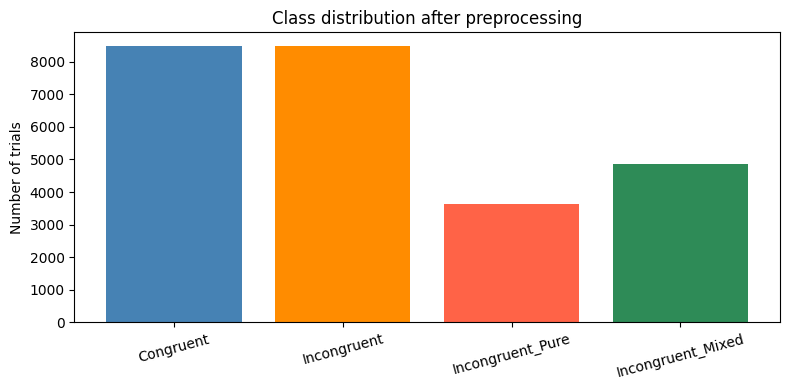

In [84]:
display(df_subject_summary)

class_counts = {
    "Congruent": int(np.sum(y_detail == "congruent")),
    "Incongruent": int(np.sum(y_detail != "congruent")),
    "Incongruent_Pure": int(np.sum(y_detail == "Incongruent_Pure")),
    "Incongruent_Mixed": int(np.sum(y_detail == "Incongruent_Mixed")),
}

plt.figure(figsize=(8, 4))
plt.bar(class_counts.keys(), class_counts.values(), color=["steelblue", "darkorange", "tomato", "seagreen"])
plt.xticks(rotation=15)
plt.ylabel("Number of trials")
plt.title("Class distribution after preprocessing")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_distribution_after_preprocessing.png", dpi=300, bbox_inches="tight")
plt.show()

Outliers detected: 896 of 16942 (5.29%)
Note: outliers are not removed in this release.


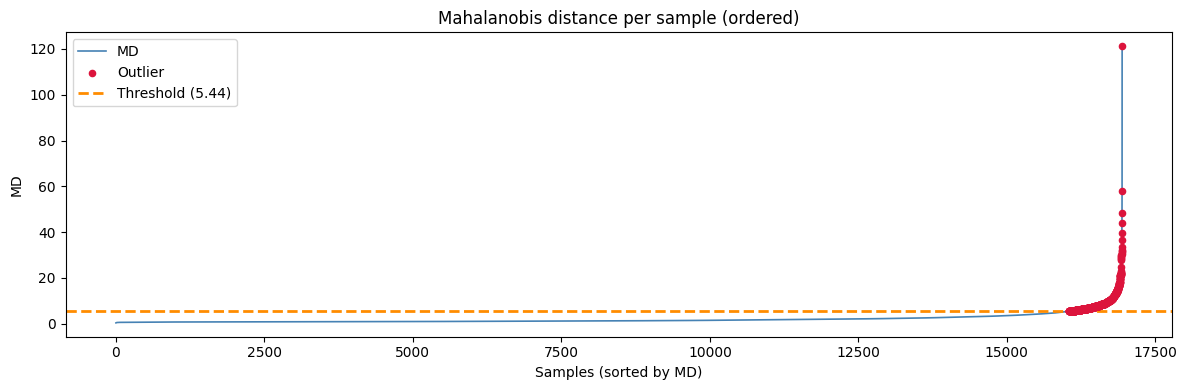

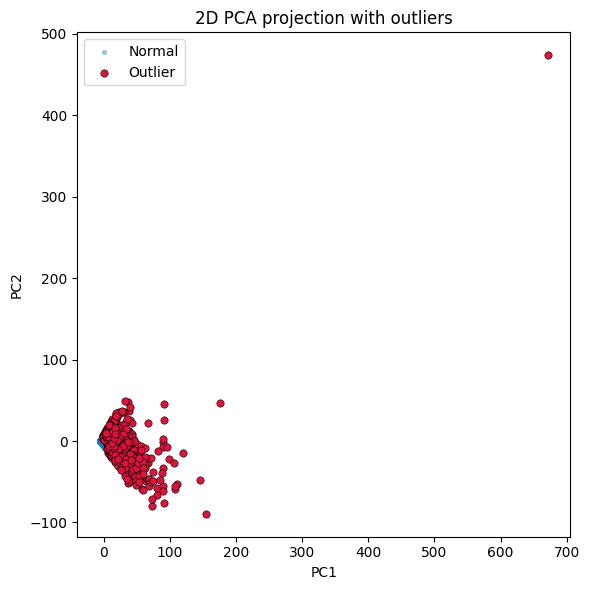

In [85]:
def mahalanobis_outliers(data, alpha=0.999):
    scaler = StandardScaler()
    data_scaled = scaler.fit_transform(data)

    pca_m = PCA(n_components=0.95, random_state=42)
    data_pca = pca_m.fit_transform(data_scaled)

    mean = np.mean(data_pca, axis=0)
    cov = np.cov(data_pca, rowvar=False)
    inv_cov = np.linalg.pinv(cov)

    diff = data_pca - mean
    md2 = np.einsum("ij,jk,ik->i", diff, inv_cov, diff)
    md = np.sqrt(np.clip(md2, 0, None))

    threshold = np.sqrt(chi2.ppf(alpha, df=data_pca.shape[1]))
    return md, md > threshold, threshold, data_pca


md_values, is_outlier, md_threshold, data_pca = mahalanobis_outliers(X)
print(f"Outliers detected: {is_outlier.sum()} of {len(X)} ({is_outlier.mean() * 100:.2f}%)")
print("Note: outliers are not removed in this release.")

# --- Plot 1: Ordered Mahalanobis distance ---
order = np.argsort(md_values)
md_sorted = md_values[order]
out_sorted = is_outlier[order]

plt.figure(figsize=(12, 4))
plt.plot(md_sorted, color="steelblue", lw=1.2, label="MD")
plt.scatter(
    np.where(out_sorted)[0],
    md_sorted[out_sorted],
    color="crimson",
    s=20,
    label="Outlier",
    zorder=3,
)
plt.axhline(md_threshold, color="darkorange", ls="--", lw=2, label=f"Threshold ({md_threshold:.2f})")
plt.title("Mahalanobis distance per sample (ordered)")
plt.xlabel("Samples (sorted by MD)")
plt.ylabel("MD")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "mahalanobis_distance_ordered.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Plot 2: 2D PCA projection with outliers ---
plt.figure(figsize=(6, 6))
plt.scatter(
    data_pca[~is_outlier, 0],
    data_pca[~is_outlier, 1],
    s=8,
    alpha=0.35,
    label="Normal",
)
plt.scatter(
    data_pca[is_outlier, 0],
    data_pca[is_outlier, 1],
    s=28,
    c="crimson",
    edgecolors="k",
    linewidths=0.4,
    label="Outlier",
)
plt.title("2D PCA projection with outliers")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pca_2d_outlier_visualization.png", dpi=300, bbox_inches="tight")
plt.show()

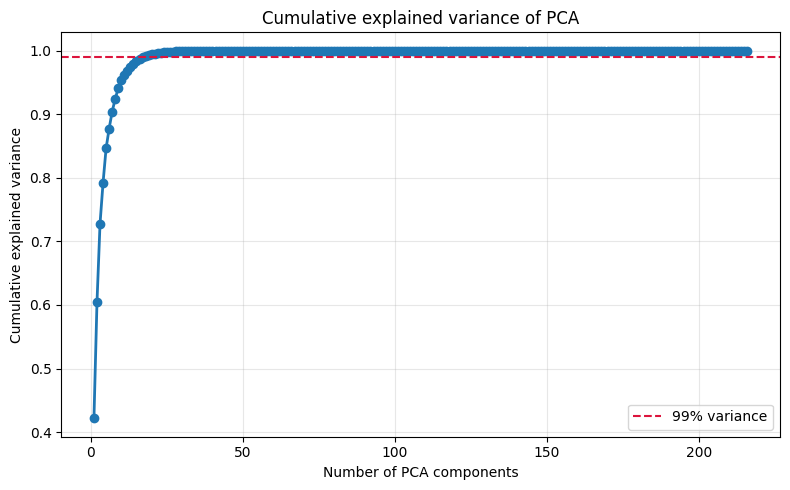

Components for 70% variance: 3
Components for 80% variance: 5
Components for 90% variance: 7
Components for 95% variance: 10
Components for 99% variance: 18
Components for 99.9% variance: 29


In [86]:
X_pca_source = X.copy()

X_scaled = StandardScaler().fit_transform(X_pca_source)
pca_full = PCA().fit(X_scaled)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components = np.arange(1, len(cum_var) + 1)

plt.figure(figsize=(8, 5))
plt.plot(n_components, cum_var, marker="o", lw=2)
plt.axhline(0.99, color="crimson", ls="--", lw=1.5, label="99% variance")
plt.xlabel("Number of PCA components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative explained variance of PCA")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cumulative_pca_variance.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Components for 70% variance: {np.searchsorted(cum_var, 0.70) + 1}")
print(f"Components for 80% variance: {np.searchsorted(cum_var, 0.80) + 1}")
print(f"Components for 90% variance: {np.searchsorted(cum_var, 0.90) + 1}")
print(f"Components for 95% variance: {np.searchsorted(cum_var, 0.95) + 1}")
print(f"Components for 99% variance: {np.searchsorted(cum_var, 0.99) + 1}")
print(f"Components for 99.9% variance: {np.searchsorted(cum_var, 0.999) + 1}")

## Modeling by subject

The analysis is done subject by subject. For each individual, undersampling is applied within the same subject and then cross-validation is done with several base models to compare families of classifiers.

The goal is to report the mean macro accuracy and F1 across all subjects for each model family. Out-of-fold predicted probabilities are also collected to generate ROC and Precision-Recall curves.

In [87]:
SUBJECT_MODEL_SPECS = {
    "LR": {
        "factory": lambda: LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42),
    },
    "LDA": {
        "factory": lambda: LDA(priors=[0.5, 0.5], solver="svd"),
    },
    "RF": {
        "factory": lambda: RandomForestClassifier(
            n_estimators=200,
            max_depth=16,
            min_samples_leaf=3,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1,
        ),
    },
    "XGB": {
        "factory": lambda: XGBClassifier(
            n_estimators=220,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1,
        ),
    },
    "LGBM": {
        "factory": lambda: LGBMClassifier(
            n_estimators=260,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            subsample=0.9,
            colsample_bytree=0.8,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1,
            verbose=-1,
        ),
    },
}


def build_subject_pipeline(model_name):
    spec = SUBJECT_MODEL_SPECS[model_name]
    return Pipeline(
        [
            ("log1p", FunctionTransformer(np.log1p, validate=False)),
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=0.99, random_state=42)),
            ("model", spec["factory"]()),
        ]
    )


def undersample_chronological(X_s, y_s, seed=42):
    n_min = min(int((y_s == 0).sum()), int((y_s == 1).sum()))
    idx_0 = np.where(y_s == 0)[0]
    idx_1 = np.where(y_s == 1)[0]
    rng = np.random.default_rng(seed)
    keep_idx = np.concatenate([rng.choice(idx_0, n_min, replace=False), rng.choice(idx_1, n_min, replace=False)])
    keep_idx.sort()  # Keep original time order
    return X_s[keep_idx], y_s[keep_idx]


subject_ids = np.unique(subj_list)
subject_rows = []
subject_model_rows = []

# Accumulate out-of-fold predictions per model for ROC/PR curves
model_predictions = {name: {"y_true": [], "y_prob": []} for name in SUBJECT_MODEL_SPECS}

print("Subject-by-subject evaluation (with temporal CV and chronological undersampling):")
print(f"Models: {', '.join(SUBJECT_MODEL_SPECS.keys())}")
print(f"Total subjects: {len(subject_ids)}")

for subj in subject_ids:
    subj_idx = np.where(subj_list == subj)[0]
    X_subj = X[subj_idx]
    y_subj = y[subj_idx]

    # Undersample while maintaining chronological order
    X_subj_bal, y_subj_bal = undersample_chronological(X_subj, y_subj, seed=42)
    class_counts = np.bincount(y_subj_bal, minlength=2)
    min_class = int(class_counts[class_counts > 0].min())
    n_splits_subj = min(5, min_class)

    if n_splits_subj < 2:
        print(f"{subj}: skipped due to insufficient samples in a class ({class_counts.tolist()}).")
        continue

    try:
        # Chronological / temporal cross-validation (no shuffling, respects actual order)
        subj_cv = list(temporal_stratified_splits(y_subj_bal, n_splits_subj))
    except ValueError as e:
        print(f"{subj}: skipped — unable to construct valid temporal splits ({e})")
        continue

    print(f"\n{subj} | raw={len(y_subj)} | balanced={len(y_subj_bal)} | C={class_counts[0]} | I={class_counts[1]}")

    for model_name in SUBJECT_MODEL_SPECS:
        subj_pipeline = build_subject_pipeline(model_name)
        subj_results = cross_validate(
            subj_pipeline,
            X_subj_bal,
            y_subj_bal,
            cv=subj_cv,
            scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
            n_jobs=-1,
        )

        # Collect out-of-fold predicted probabilities for ROC/PR curves
        try:
            y_probs_fold = []
            y_true_fold = []
            for train_idx, test_idx in subj_cv:
                clf = build_subject_pipeline(model_name)
                clf.fit(X_subj_bal[train_idx], y_subj_bal[train_idx])
                y_probs_fold.append(clf.predict_proba(X_subj_bal[test_idx])[:, 1])
                y_true_fold.append(y_subj_bal[test_idx])
            y_prob = np.concatenate(y_probs_fold)
            y_true_s = np.concatenate(y_true_fold)
            model_predictions[model_name]["y_true"].append(y_true_s)
            model_predictions[model_name]["y_prob"].append(y_prob)
        except Exception:
            pass  # Some models may not support predict_proba

        row = {
            "subject": subj,
            "model": model_name,
            "n_samples_raw": int(len(y_subj)),
            "n_samples_bal": int(len(y_subj_bal)),
            "n_c": int((y_subj_bal == 0).sum()),
            "n_i": int((y_subj_bal == 1).sum()),
            "acc_mean": float(np.mean(subj_results["test_accuracy"])),
            "acc_std": float(np.std(subj_results["test_accuracy"])),
            "f1_mean": float(np.mean(subj_results["test_f1_macro"])),
            "f1_std": float(np.std(subj_results["test_f1_macro"])),
        }
        subject_model_rows.append(row)

        print(
            f"  {model_name:>4} | ACC={row['acc_mean']:.3f}\u00b1{row['acc_std']:.3f} | "
            f"F1={row['f1_mean']:.3f}\u00b1{row['f1_std']:.3f}"
        )

    best_subj = sorted(
        [r for r in subject_model_rows if r["subject"] == subj],
        key=lambda r: (r["f1_mean"], r["acc_mean"]),
        reverse=True,
    )[0]
    subject_rows.append(best_subj)

subject_acc_mean = float(np.mean([r["acc_mean"] for r in subject_rows]))
subject_acc_std = float(np.std([r["acc_mean"] for r in subject_rows]))
subject_f1_mean = float(np.mean([r["f1_mean"] for r in subject_rows]))
subject_f1_std = float(np.std([r["f1_mean"] for r in subject_rows]))

df_subject_results = pd.DataFrame(subject_rows).sort_values(["subject", "model"]).reset_index(drop=True)
df_model_results = pd.DataFrame(subject_model_rows).sort_values(["subject", "model"]).reset_index(drop=True)
df_subject_results.to_csv(TABLES_DIR / "subject_best_models.csv", index=False)
df_model_results.to_csv(TABLES_DIR / "subject_model_scores.csv", index=False)

print(f"Saved table: {TABLES_DIR / 'subject_best_models.csv'}")
print(f"Saved table: {TABLES_DIR / 'subject_model_scores.csv'}")
print("\nGlobal subject-by-subject summary (best model per subject):")
print(f"Mean accuracy across subjects: {subject_acc_mean:.3f} \u00b1 {subject_acc_std:.3f}")
print(f"Mean macro F1 across subjects: {subject_f1_mean:.3f} \u00b1 {subject_f1_std:.3f}")
print(f"Evaluated subjects: {len(subject_rows)}")

Subject-by-subject evaluation (with temporal CV and chronological undersampling):
Models: LR, LDA, RF, XGB, LGBM
Total subjects: 47

P002 | raw=288 | balanced=288 | C=144 | I=144
    LR | ACC=0.529±0.036 | F1=0.527±0.037
   LDA | ACC=0.500±0.066 | F1=0.498±0.065
    RF | ACC=0.537±0.052 | F1=0.535±0.051
   XGB | ACC=0.475±0.053 | F1=0.473±0.054
  LGBM | ACC=0.500±0.063 | F1=0.498±0.063

P003 | raw=382 | balanced=382 | C=191 | I=191
    LR | ACC=0.510±0.084 | F1=0.504±0.084
   LDA | ACC=0.510±0.080 | F1=0.506±0.080
    RF | ACC=0.532±0.062 | F1=0.530±0.063
   XGB | ACC=0.547±0.023 | F1=0.545±0.024
  LGBM | ACC=0.544±0.033 | F1=0.538±0.040

P004 | raw=436 | balanced=436 | C=218 | I=218
    LR | ACC=0.507±0.033 | F1=0.505±0.032
   LDA | ACC=0.499±0.035 | F1=0.497±0.034
    RF | ACC=0.535±0.034 | F1=0.518±0.044
   XGB | ACC=0.504±0.061 | F1=0.496±0.061
  LGBM | ACC=0.535±0.084 | F1=0.532±0.083

P005 | raw=332 | balanced=332 | C=166 | I=166
    LR | ACC=0.486±0.044 | F1=0.480±0.043
   LDA |

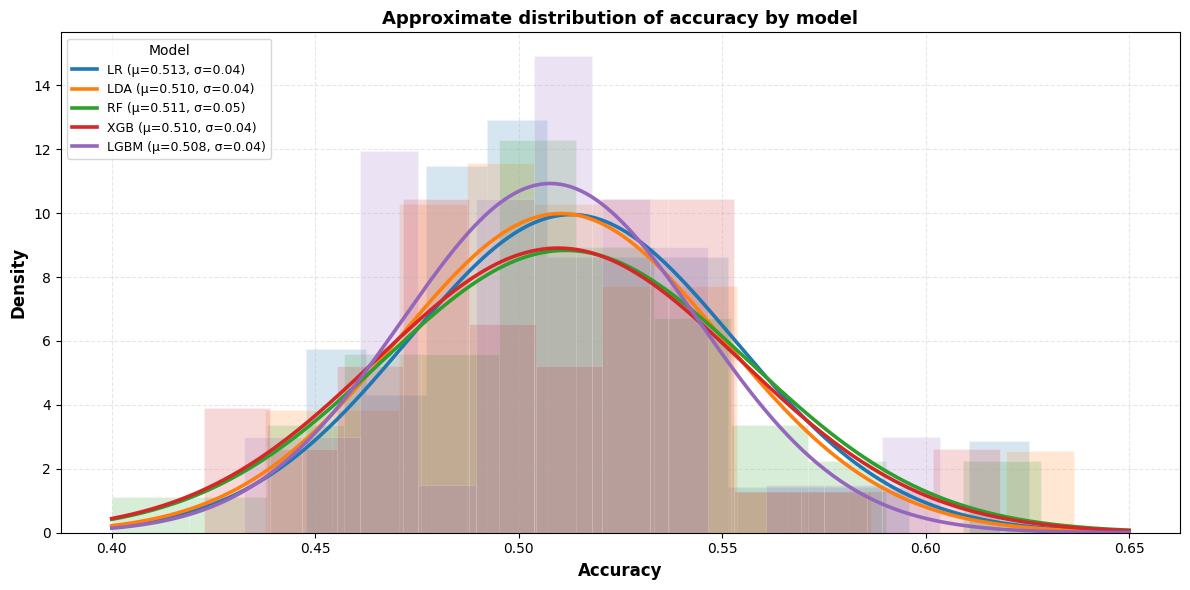

In [88]:
models = sorted(df_model_results["model"].unique())
cmap = plt.get_cmap("tab10")
colors = [cmap(i) for i in range(len(models))]

plt.figure(figsize=(12, 6))
ax = plt.gca()

x_min, x_max = 0.4, 0.65
x_grid = np.linspace(x_min, x_max, 400)
models_ordered = ["LR", "LDA", "RF", "XGB", "LGBM"]

for i, model in enumerate(models_ordered):
    accs = df_model_results.loc[df_model_results["model"] == model, "acc_mean"].dropna().values
    if len(accs) == 0:
        continue

    color = colors[i % len(colors)]
    mu = float(accs.mean())
    sigma = float(accs.std(ddof=1)) if len(accs) > 1 else 0.0
    sigma = max(sigma, 1e-3)

    # Histogram kept light in the background; Gaussian curve carries the shape
    ax.hist(
        accs,
        bins=12,
        density=True,
        alpha=0.18,
        color=color,
        edgecolor="white",
        linewidth=0.6,
    )
    ax.plot(
        x_grid,
        norm.pdf(x_grid, mu, sigma),
        color=color,
        lw=2.6,
        label=f"{model} (\u03bc={mu:.3f}, \u03c3={sigma:.2f})",
    )

ax.set_xlabel("Accuracy", fontsize=12, fontweight="bold")
ax.set_ylabel("Density", fontsize=12, fontweight="bold")
ax.set_title("Approximate distribution of accuracy by model", fontsize=13, fontweight="bold")
ax.legend(loc="upper left", fontsize=9, frameon=True, title="Model")
ax.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "acc_histograms_models.png", dpi=300, bbox_inches="tight")
plt.show()

## ROC-AUC and Precision-Recall Curves

These plots show the pooled out-of-fold predictions across all subjects for each model family.

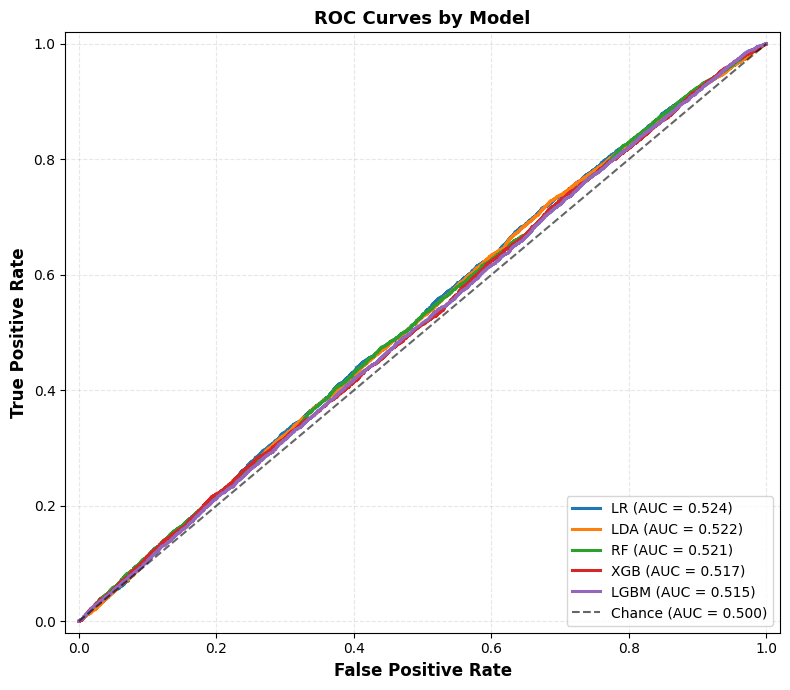

ROC-AUC per model (pooled across subjects):
  LR: 0.5235
  LDA: 0.5215
  RF: 0.5213
  XGB: 0.5166
  LGBM: 0.5145


In [94]:
fig, ax = plt.subplots(figsize=(8, 7))
cmap = plt.get_cmap("tab10")

for i, model_name in enumerate(["LR", "LDA", "RF", "XGB", "LGBM"]):
    preds = model_predictions[model_name]
    if not preds["y_true"]:
        continue
    y_true_all = np.concatenate(preds["y_true"])
    y_prob_all = np.concatenate(preds["y_prob"])
    fpr, tpr, _ = roc_curve(y_true_all, y_prob_all)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, lw=2.2, color=cmap(i), label=f"{model_name} (AUC = {roc_auc:.3f})")

ax.plot([0, 1], [0, 1], "k--", lw=1.5, alpha=0.6, label="Chance (AUC = 0.500)")
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])
ax.set_xlabel("False Positive Rate", fontsize=12, fontweight="bold")
ax.set_ylabel("True Positive Rate", fontsize=12, fontweight="bold")
ax.set_title("ROC Curves by Model", fontsize=13, fontweight="bold")
ax.legend(loc="lower right", fontsize=10, frameon=True)
ax.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "roc_curves_models.png", dpi=300, bbox_inches="tight")
plt.show()

# Print AUC values
print("ROC-AUC per model (pooled across subjects):")
for model_name in ["LR", "LDA", "RF", "XGB", "LGBM"]:
    preds = model_predictions[model_name]
    if not preds["y_true"]:
        continue
    y_true_all = np.concatenate(preds["y_true"])
    y_prob_all = np.concatenate(preds["y_prob"])
    fpr, tpr, _ = roc_curve(y_true_all, y_prob_all)
    print(f"  {model_name}: {auc(fpr, tpr):.4f}")

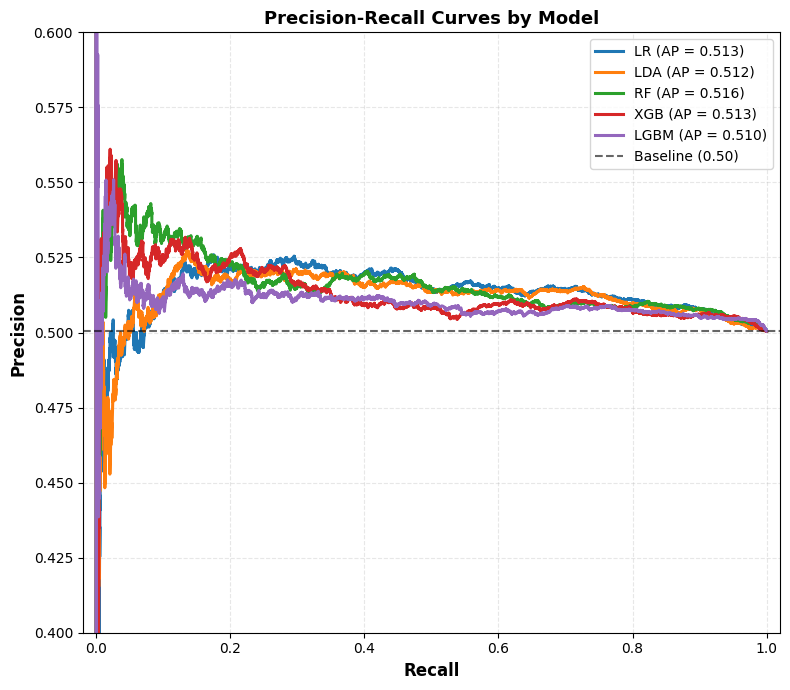

Average Precision per model (pooled across subjects):
  LR: 0.5132
  LDA: 0.5118
  RF: 0.5157
  XGB: 0.5127
  LGBM: 0.5103


In [93]:
fig, ax = plt.subplots(figsize=(8, 7))
cmap = plt.get_cmap("tab10")

# Compute baseline (prevalence of positive class)
all_y = []
for preds in model_predictions.values():
    if preds["y_true"]:
        all_y.extend([np.concatenate(preds["y_true"])])
if all_y:
    baseline = np.concatenate(all_y).mean()
else:
    baseline = 0.5

for i, model_name in enumerate(["LR", "LDA", "RF", "XGB", "LGBM"]):
    preds = model_predictions[model_name]
    if not preds["y_true"]:
        continue
    y_true_all = np.concatenate(preds["y_true"])
    y_prob_all = np.concatenate(preds["y_prob"])
    precision, recall, _ = precision_recall_curve(y_true_all, y_prob_all)
    ap = average_precision_score(y_true_all, y_prob_all)
    ax.plot(recall, precision, lw=2.2, color=cmap(i), label=f"{model_name} (AP = {ap:.3f})")

ax.axhline(baseline, color="k", ls="--", lw=1.5, alpha=0.6, label=f"Baseline ({baseline:.2f})")
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([0.4, 0.6])
ax.set_xlabel("Recall", fontsize=12, fontweight="bold")
ax.set_ylabel("Precision", fontsize=12, fontweight="bold")
ax.set_title("Precision-Recall Curves by Model", fontsize=13, fontweight="bold")
ax.legend(loc="upper right", fontsize=10, frameon=True)
ax.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr_curves_models.png", dpi=300, bbox_inches="tight")
plt.show()

# Print AP values
print("Average Precision per model (pooled across subjects):")
for model_name in ["LR", "LDA", "RF", "XGB", "LGBM"]:
    preds = model_predictions[model_name]
    if not preds["y_true"]:
        continue
    y_true_all = np.concatenate(preds["y_true"])
    y_prob_all = np.concatenate(preds["y_prob"])
    ap = average_precision_score(y_true_all, y_prob_all)
    print(f"  {model_name}: {ap:.4f}")